In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/sample_submission.csv
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip
/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/test.zip


In [2]:
import os
import glob
import zipfile
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
possible_paths = [
    "/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip",
    "../input/dogs-vs-cats-redux-kernels-edition/train.zip",
    "./train.zip"
]

zip_path = None
for p in possible_paths:
    if os.path.exists(p):
        zip_path = p
        break

if zip_path is None:
    raise FileNotFoundError("Could not find train.zip. Check your Kaggle dataset input path.")

extract_dir = "/kaggle/working/train_extracted"
if not os.path.exists(extract_dir):
    print(f"Unzipping {zip_path} into {extract_dir}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
else:
    print(f"Directory {extract_dir} already exists. Skipping extraction.")

# Find directory containing cat.*.jpg and dog.*.jpg
img_dir = extract_dir
sub_train = os.path.join(extract_dir, "train")
if os.path.exists(sub_train):
    img_dir = sub_train


class KaggleReduxCatsDogs(Dataset):
    def __init__(self, folder_path, transform=None):
        self.files = glob.glob(os.path.join(folder_path, "*.jpg"))
        self.transform = transform
        self.samples = []
        for p in self.files:
            fname = os.path.basename(p).lower()
            if fname.startswith("cat"):
                self.samples.append((p, 0))
            elif fname.startswith("dog"):
                self.samples.append((p, 1))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label


img_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

full_dataset = KaggleReduxCatsDogs(img_dir, transform=img_transform)
print(f"Loaded {len(full_dataset)} total labeled images from {img_dir}.")

# 80/20 train/test split on labeled images
train_len = int(0.8 * len(full_dataset))
test_len = len(full_dataset) - train_len
train_set, test_set = random_split(
    full_dataset, [train_len, test_len],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=128, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=2)

Unzipping /kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip into /kaggle/working/train_extracted...
Loaded 25000 total labeled images from /kaggle/working/train_extracted/train.


In [4]:
weights = models.ResNet18_Weights.DEFAULT
backbone = models.resnet18(weights=weights)
backbone.fc = nn.Identity()  # 512-D
backbone = backbone.to(device)
backbone.eval()

@torch.no_grad()
def extract_embeddings(loader):
    all_feats, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        feats = backbone(imgs)
        all_feats.append(feats.cpu())
        all_labels.append(labels)
    return torch.cat(all_feats, dim=0).to(device), torch.cat(all_labels, dim=0).to(device)

print("Extracting frozen ResNet-18 features...")
X_train, y_train = extract_embeddings(train_loader)
X_test, y_test = extract_embeddings(test_loader)
print(f"Features ready -> X_train: {X_train.shape}, X_test: {X_test.shape}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 215MB/s]


Extracting frozen ResNet-18 features...
Features ready -> X_train: torch.Size([20000, 512]), X_test: torch.Size([5000, 512])


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim

class SmallNodeNet(nn.Module):
    def __init__(self, in_features, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

class TreeNeuron(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = SmallNodeNet(in_features)
        self.child_A = None
        self.child_B = None
        self.w_A = nn.Parameter(torch.tensor(0.0))
        self.w_B = nn.Parameter(torch.tensor(0.0))

    def compute_net(self, x):
        net = self.model(x)
        if self.child_A is not None:
            # Child A predicts 1 for samples that need a positive boost
            out_A = (self.child_A.compute_net(x) >= 0.0).float()
            net = net + torch.relu(self.w_A) * out_A
        if self.child_B is not None:
            # Child B predicts 1 for samples that need negative suppression
            out_B = (self.child_B.compute_net(x) >= 0.0).float()
            net = net - torch.relu(torch.abs(self.w_B)) * out_B
        return net

    def forward(self, x):
        return (self.compute_net(x) >= 0.0).float()

def count_tree_nodes(node):
    if node is None:
        return 0
    return 1 + count_tree_nodes(node.child_A) + count_tree_nodes(node.child_B)

def train_node_weighted(model, X, y, epochs=100, lr=0.01):
    num_pos = (y == 1).sum().float()
    num_neg = (y == 0).sum().float()
    
    if num_pos == 0 or num_neg == 0:
        return  # Pure subset, no training needed
        
    # Heavily weight positive error class to defeat majority class collapse
    pos_weight = (num_neg / (num_pos + 1e-5)).clamp(min=1.0, max=50.0)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    
    y_f = y.float()
    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y_f)
        loss.backward()
        optimizer.step()

def build_tree_node(X, y, depth=0, max_depth=12):
    node = TreeNeuron(in_features=X.shape[1]).to(device)
    
    # 1. Train current node's classifier
    train_node_weighted(node.model, X, y, epochs=80, lr=0.005)

    with torch.no_grad():
        base_logits = node.model(X)
        preds = (base_logits >= 0.0).long()
        errors = (preds != y)

    # If 100% correct or reached depth limit, return leaf
    if not errors.any() or depth >= max_depth or len(X) <= 2:
        return node

    # Split errors according to Jayadeva categories
    # C3: Actual 0, Desired 1 (Needs boost from Child A)
    # C4: Actual 1, Desired 0 (Needs suppression from Child B)
    mask_c3 = (preds == 0) & (y == 1)
    mask_c4 = (preds == 1) & (y == 0)

    # ---------------------------------------------
    # Child A: Learns to detect C3 errors
    # ---------------------------------------------
    if mask_c3.any():
        # Exclude C2 (samples correctly classified as 1 are "don't care" for A)
        mask_c2 = (preds == 1) & (y == 1)
        active_A = ~mask_c2
        
        X_A = X[active_A]
        # Target is 1 ONLY for C3, 0 for everything else in this active pool
        y_A = torch.zeros(active_A.sum(), device=device, dtype=torch.long)
        c3_sub = mask_c3[active_A]
        y_A[c3_sub] = 1

        node.child_A = build_tree_node(X_A, y_A, depth=depth + 1, max_depth=max_depth)
        
        # Calculate corrective weight w_A to flip the negative net input of C3
        with torch.no_grad():
            neg_deficit = torch.abs(base_logits[mask_c3])
            node.w_A.data = torch.max(neg_deficit) + 2.0

    # ---------------------------------------------
    # Child B: Learns to detect C4 errors
    # ---------------------------------------------
    if mask_c4.any():
        # Exclude C1 (samples correctly classified as 0 are "don't care" for B)
        mask_c1 = (preds == 0) & (y == 0)
        active_B = ~mask_c1

        X_B = X[active_B]
        # Target is 1 ONLY for C4, 0 for everything else in this active pool
        y_B = torch.zeros(active_B.sum(), device=device, dtype=torch.long)
        c4_sub = mask_c4[active_B]
        y_B[c4_sub] = 1

        node.child_B = build_tree_node(X_B, y_B, depth=depth + 1, max_depth=max_depth)

        # Calculate corrective weight w_B to suppress positive net input of C4
        with torch.no_grad():
            pos_surplus = base_logits[mask_c4]
            node.w_B.data = torch.max(pos_surplus) + 2.0

    return node

In [6]:
print("\n--- Sweeping Tree Capacities for Double Descent ---")
depth_levels = [1, 2, 3, 5, 7, 10, 15, 20]
train_errors, test_errors, total_nodes = [], [], []

for d in depth_levels:
    tree = build_tree_node(X_train, y_train, max_depth=d)
    with torch.no_grad():
        tr_preds = tree(X_train)
        te_preds = tree(X_test)
        tr_err = 1.0 - (tr_preds == y_train).float().mean().item()
        te_err = 1.0 - (te_preds == y_test).float().mean().item()

    n_nodes = count_tree_nodes(tree)
    train_errors.append(tr_err)
    test_errors.append(te_err)
    total_nodes.append(n_nodes)

    print(f"Depth: {d:2d} | Nodes: {n_nodes:4d} | "
          f"Train Acc: {(1 - tr_err)*100:6.2f}% | Test Acc: {(1 - te_err)*100:6.2f}%")


--- Sweeping Tree Capacities for Double Descent ---
Depth:  1 | Nodes:    3 | Train Acc:  95.69% | Test Acc:  95.58%
Depth:  2 | Nodes:    6 | Train Acc:  96.43% | Test Acc:  95.78%
Depth:  3 | Nodes:    9 | Train Acc:  95.75% | Test Acc:  93.52%
Depth:  5 | Nodes:   19 | Train Acc:  98.58% | Test Acc:  94.08%
Depth:  7 | Nodes:   28 | Train Acc:  99.13% | Test Acc:  94.26%
Depth: 10 | Nodes:   34 | Train Acc: 100.00% | Test Acc:  94.88%
Depth: 15 | Nodes:   30 | Train Acc:  99.29% | Test Acc:  94.52%
Depth: 20 | Nodes:   32 | Train Acc: 100.00% | Test Acc:  94.88%


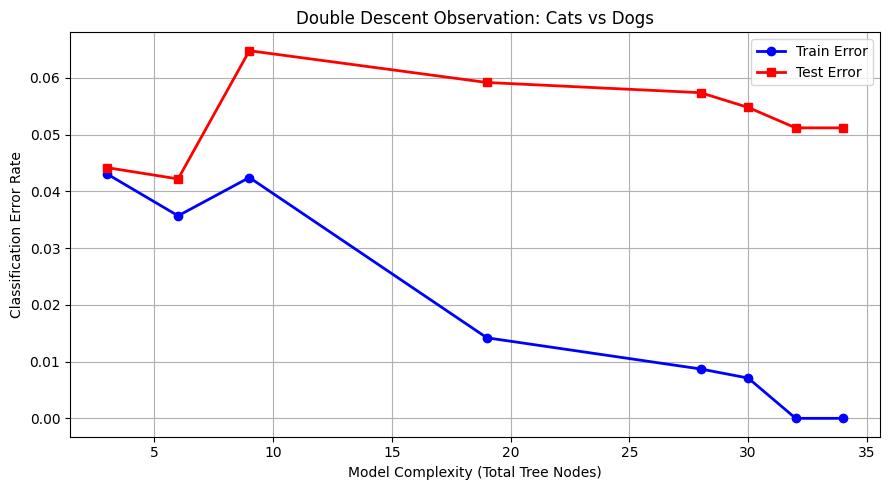

In [7]:
# 1. Zip the lists together and sort them based on the total_nodes (x-axis)
sorted_data = sorted(zip(total_nodes, train_errors, test_errors))

# 2. Unzip back into separate lists
sorted_nodes, sorted_train_err, sorted_test_err = zip(*sorted_data)

plt.figure(figsize=(9, 5))
# 3. Plot the sorted data
plt.plot(sorted_nodes, sorted_train_err, 'o-', label="Train Error", color="blue", linewidth=2)
plt.plot(sorted_nodes, sorted_test_err, 's-', label="Test Error", color="red", linewidth=2)

plt.xlabel("Model Complexity (Total Tree Nodes)")
plt.ylabel("Classification Error Rate")
plt.title("Double Descent Observation: Cats vs Dogs")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("cats_dogs_double_descent_sorted.png")
plt.show()


--- Generating Node Receptive Field Saliency Map ---
Saved receptive field to cats_dogs_receptive_field.png


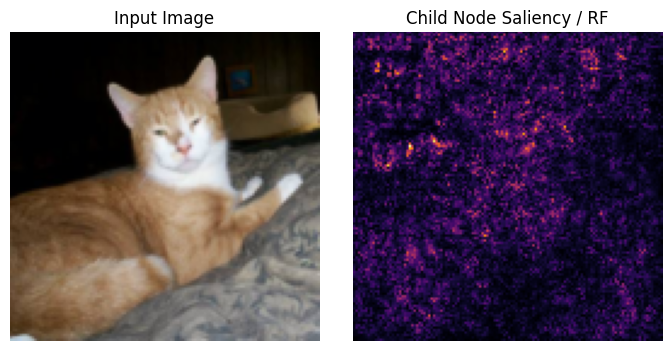

In [8]:
print("\n--- Generating Node Receptive Field Saliency Map ---")
# Use 'tree' which is already in memory from the last loop
target_node = tree.child_A if tree.child_A is not None else tree

# Take sample image from test set
sample_img, _ = test_set[0]
sample_tensor = sample_img.unsqueeze(0).to(device)
sample_tensor.requires_grad = True

emb = backbone(sample_tensor)
logit = target_node.model(emb).squeeze()
logit.backward()

saliency, _ = torch.max(sample_tensor.grad.data.abs(), dim=1)
saliency = saliency.squeeze().cpu().numpy()
saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
img_disp = sample_img.permute(1, 2, 0).numpy()
img_disp = np.clip((img_disp * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]), 0, 1)

axes[0].imshow(img_disp)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(saliency, cmap="inferno")
axes[1].set_title("Child Node Saliency / RF")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("cats_dogs_receptive_field.png")
print("Saved receptive field to cats_dogs_receptive_field.png")

In [9]:
print("\n--- Pruning Sparse Nodes ---")
def prune_sparse_nodes(node, X_eval, min_corrections=5):
    if node is None:
        return None
    node.child_A = prune_sparse_nodes(node.child_A, X_eval, min_corrections)
    node.child_B = prune_sparse_nodes(node.child_B, X_eval, min_corrections)

    if node.child_A is not None:
        with torch.no_grad():
            hits = (node.child_A(X_eval) >= 0.5).sum().item()
        if hits < min_corrections:
            node.child_A = None
            node.w_A.data.fill_(0.0)

    if node.child_B is not None:
        with torch.no_grad():
            hits = (node.child_B(X_eval) >= 0.5).sum().item()
        if hits < min_corrections:
            node.child_B = None
            node.w_B.data.fill_(0.0)
    return node

nodes_before = count_tree_nodes(tree)
pruned_tree = prune_sparse_nodes(tree, X_test, min_corrections=5)
nodes_after = count_tree_nodes(pruned_tree)

with torch.no_grad():
    pruned_test_acc = (pruned_tree(X_test) == y_test).float().mean().item() * 100

print(f"Nodes before pruning: {nodes_before} | After pruning: {nodes_after}")
print(f"Test Accuracy after pruning: {pruned_test_acc:.2f}%")


--- Pruning Sparse Nodes ---
Nodes before pruning: 32 | After pruning: 25
Test Accuracy after pruning: 94.86%
